# XAUUSD H1 — Baseline Regime Detection & N-Method Performance

This notebook repeats the earlier D1 regime-analysis workflow on hourly XAUUSD data.

## Research workflow

1. Classify each H1 candle as **Bullish**, **Bearish**, **Sideways**, or **Unclassified** using EMA(50), EMA(200), and ADX(14).
2. Measure Bullish N, Bearish N, and Ranging N performance within each detected regime.
3. Compare original unfiltered performance against a pre-defined matched-regime filter:
   - Bullish N only in Bullish regimes.
   - Bearish N only in Bearish regimes.
   - Ranging N only in Sideways regimes.

Run `01_N_Method_Backtest_H1.ipynb` first to generate the trade-level file.

> **H1 parameter interpretation:** the numerical indicator parameters are unchanged from D1, but their durations are measured in H1 bars. EMA(50) and EMA(200) use 50 and 200 hourly bars; ADX(14) uses hourly bars. This is not a calendar-time-equivalent D1 model.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "XAUUSD_H1.csv"
TRADES_PATH = PROJECT_ROOT / "outputs" / "XAUUSD_H1_N_method_trades.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

raw = pd.read_csv(DATA_PATH, header=None)
cols = ["Date", "Open", "High", "Low", "Close"] + (["Volume"] if raw.shape[1] >= 6 else [])
raw = raw.iloc[:, :len(cols)].copy()
raw.columns = cols
raw["Date"] = pd.to_datetime(raw["Date"], errors="coerce")
for col in ["Open", "High", "Low", "Close"]:
    raw[col] = pd.to_numeric(raw[col], errors="coerce")
data = (raw.dropna(subset=["Date", "Open", "High", "Low", "Close"])
            .sort_values("Date").drop_duplicates("Date").set_index("Date"))

if not TRADES_PATH.exists():
    raise FileNotFoundError("Run notebooks/01_N_Method_Backtest_H1.ipynb first.")
trades = pd.read_csv(TRADES_PATH)
for col in ["signal_date", "entry_date", "exit_date"]:
    trades[col] = pd.to_datetime(trades[col])

print(f"Data: {len(data):,} H1 bars | {data.index.min()} to {data.index.max()}")

Data: 100,000 H1 bars | 2010-02-22 18:00:00 to 2026-11-12 06:00:00


## 1. Baseline regime definition

The classifier is intentionally simple and interpretable:

| Regime | Rule |
|---|---|
| Bullish | ADX(14) ≥ 20 and EMA(50) > EMA(200) |
| Bearish | ADX(14) ≥ 20 and EMA(50) < EMA(200) |
| Sideways | ADX(14) < 20 |
| Unclassified | Required indicator values are not yet available |

EMA alignment supplies directional bias; ADX estimates trend strength and does not provide direction by itself. The model uses values available at the close of each H1 candle.

In [2]:
# Calculate EMA(50), EMA(200), and Wilder-style ADX(14).
data["EMA50"] = data["Close"].ewm(span=50, adjust=False, min_periods=50).mean()
data["EMA200"] = data["Close"].ewm(span=200, adjust=False, min_periods=200).mean()

period = 14
prev_close = data["Close"].shift(1)
true_range = pd.concat([
    data["High"] - data["Low"],
    (data["High"] - prev_close).abs(),
    (data["Low"] - prev_close).abs(),
], axis=1).max(axis=1)
up_move = data["High"].diff()
down_move = -data["Low"].diff()
plus_dm = pd.Series(np.where((up_move > down_move) & (up_move > 0), up_move, 0.0), index=data.index)
minus_dm = pd.Series(np.where((down_move > up_move) & (down_move > 0), down_move, 0.0), index=data.index)
smoothed_tr = true_range.ewm(alpha=1/period, adjust=False, min_periods=period).mean()
smoothed_plus_dm = plus_dm.ewm(alpha=1/period, adjust=False, min_periods=period).mean()
smoothed_minus_dm = minus_dm.ewm(alpha=1/period, adjust=False, min_periods=period).mean()
data["+DI14"] = 100 * smoothed_plus_dm / smoothed_tr
data["-DI14"] = 100 * smoothed_minus_dm / smoothed_tr
dx = 100 * (data["+DI14"] - data["-DI14"]).abs() / (data["+DI14"] + data["-DI14"])
data["ADX14"] = dx.ewm(alpha=1/period, adjust=False, min_periods=period).mean()

conditions = [
    data["ADX14"] < 20,
    (data["ADX14"] >= 20) & (data["EMA50"] > data["EMA200"]),
    (data["ADX14"] >= 20) & (data["EMA50"] < data["EMA200"]),
]
data["Regime"] = np.select(conditions, ["Sideways", "Bullish", "Bearish"], default="Unclassified")
regime_order = ["Bullish", "Bearish", "Sideways", "Unclassified"]
regime_distribution = data["Regime"].value_counts().reindex(regime_order, fill_value=0).rename("Bars").to_frame()
regime_distribution["Share %"] = 100 * regime_distribution["Bars"] / len(data)
display(regime_distribution.round(2))

,Bars,Share %
Regime,,
Bullish,37711,37.71
Bearish,31640,31.64
Sideways,30461,30.46
Unclassified,188,0.19


## 2. Strategy performance within each detected regime

Each N-Method trade is assigned the regime on `signal_date`, when the setup is confirmed. The pending entry becomes active on the following H1 candle. This uses the regime known when the signal is generated, not a later regime observed at entry or exit.

In [3]:
# Attach the regime at the setup-confirmation timestamp.
trades = trades.drop(columns=["Regime"], errors="ignore").merge(
    data[["Regime"]], left_on="signal_date", right_index=True, how="left"
)
valid = trades[trades["result"].isin(["TP", "SL", "OPEN_AT_END"])].copy()
ambiguous_count = int((trades["result"] == "AMBIGUOUS_BOTH_SIDES").sum())
print(f"Valid trades included: {len(valid):,} | Ambiguous OCO signals excluded: {ambiguous_count}")


def performance_stats(group: pd.DataFrame) -> pd.Series:
    group = group[group["result"].isin(["TP", "SL", "OPEN_AT_END"])]
    if group.empty:
        return pd.Series({"Trades": 0, "Win rate %": np.nan, "Net R": 0.0,
                          "Profit factor (R)": np.nan, "Avg R": np.nan})
    gross_profit = group.loc[group["R"] > 0, "R"].sum()
    gross_loss = -group.loc[group["R"] < 0, "R"].sum()
    return pd.Series({
        "Trades": len(group),
        "Win rate %": 100 * (group["R"] > 0).mean(),
        "Net R": group["R"].sum(),
        "Profit factor (R)": gross_profit / gross_loss if gross_loss > 0 else np.inf,
        "Avg R": group["R"].mean(),
    })

strategies = ["bullish", "bearish", "ranging"]
regimes = ["Bullish", "Bearish", "Sideways", "Unclassified"]
rows = []
for strategy in strategies:
    for regime in regimes:
        subset = valid[(valid["setup"] == strategy) & (valid["Regime"] == regime)]
        rows.append({"Strategy": strategy.title() + " N", "Regime": regime,
                     **performance_stats(subset).to_dict()})
regime_performance = pd.DataFrame(rows)
display(regime_performance.round(3))

Valid trades included: 2,946 | Ambiguous OCO signals excluded: 8


,Strategy,Regime,Trades,Win rate %,Net R,Profit factor (R),Avg R
0,Bullish N,Bullish,447.0,35.794,29.536,1.102,0.066
1,Bullish N,Bearish,434.0,30.415,-43.719,0.858,-0.101
2,Bullish N,Sideways,419.0,34.368,6.491,1.023,0.015
3,Bullish N,Unclassified,2.0,50.000,1.000,2.000,0.500
4,Bearish N,Bullish,446.0,27.803,-81.805,0.752,-0.183
5,Bearish N,Bearish,363.0,28.650,-57.410,0.782,-0.158
6,Bearish N,Sideways,417.0,32.614,-16.468,0.943,-0.039
7,Bearish N,Unclassified,1.0,0.000,-1.000,0.000,-1.000
8,Ranging N,Bullish,142.0,33.803,1.985,1.021,0.014
9,Ranging N,Bearish,107.0,36.449,10.000,1.147,0.093


## 3. Compare no regime filter with the pre-defined matched-regime filter

The matched-regime mapping is specified before inspecting conditional results:

- Bullish N → Bullish regime.
- Bearish N → Bearish regime.
- Ranging N → Sideways regime.

This is a benchmark selection rule, not an optimized or proven mapping.

In [4]:
matched_regime = {"bullish": "Bullish", "bearish": "Bearish", "ranging": "Sideways"}
comparison_rows = []
for strategy in strategies:
    original = valid[valid["setup"] == strategy]
    filtered = valid[(valid["setup"] == strategy) & (valid["Regime"] == matched_regime[strategy])]
    comparison_rows.append({"Strategy": strategy.title() + " N", "Selection": "No regime filter",
                            **performance_stats(original).to_dict()})
    comparison_rows.append({"Strategy": strategy.title() + " N",
                            "Selection": f"Matched regime only ({matched_regime[strategy]})",
                            **performance_stats(filtered).to_dict()})

matched_all = pd.concat([
    valid[(valid["setup"] == strategy) & (valid["Regime"] == regime)]
    for strategy, regime in matched_regime.items()
], ignore_index=True)
comparison_rows.append({"Strategy": "All strategies", "Selection": "No regime filter",
                        **performance_stats(valid).to_dict()})
comparison_rows.append({"Strategy": "All strategies", "Selection": "Matched regime only",
                        **performance_stats(matched_all).to_dict()})
comparison = pd.DataFrame(comparison_rows)
display(comparison.round(3))

,Strategy,Selection,Trades,Win rate %,Net R,Profit factor (R),Avg R
0,Bullish N,No regime filter,1302.0,33.564,-6.692,0.992,-0.005
1,Bullish N,Matched regime only (Bullish),447.0,35.794,29.536,1.102,0.066
2,Bearish N,No regime filter,1227.0,29.666,-156.684,0.823,-0.128
3,Bearish N,Matched regime only (Bearish),363.0,28.650,-57.410,0.782,-0.158
4,Ranging N,No regime filter,417.0,36.691,41.985,1.159,0.101
5,Ranging N,Matched regime only (Sideways),167.0,39.521,31.000,1.307,0.186
6,All strategies,No regime filter,2946.0,32.383,-121.391,0.940,-0.041
7,All strategies,Matched regime only,977.0,33.777,3.125,1.005,0.003


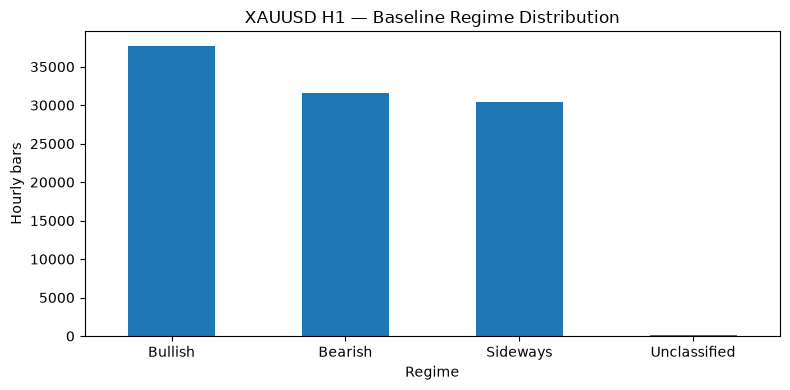

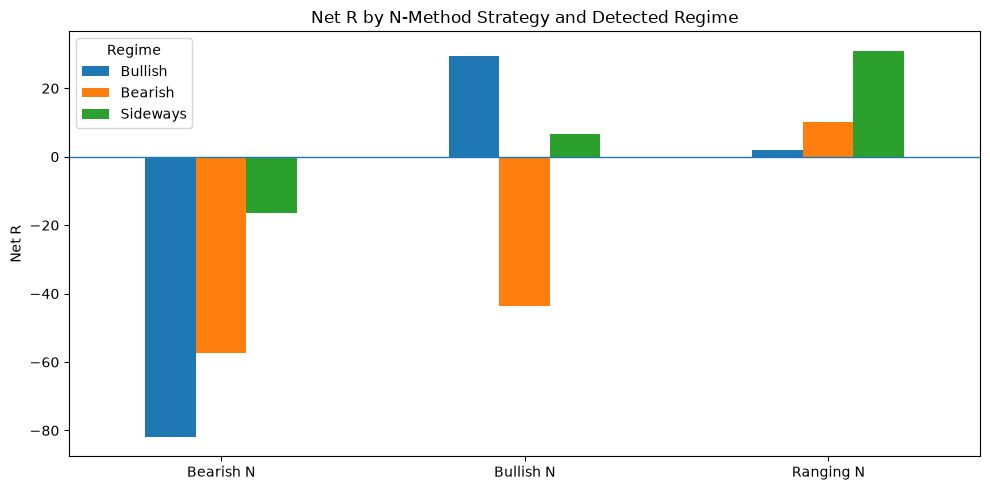

In [5]:
# Visual summaries.
ax = regime_distribution["Bars"].plot(kind="bar", figsize=(8, 4))
ax.set_title("XAUUSD H1 — Baseline Regime Distribution")
ax.set_xlabel("Regime"); ax.set_ylabel("Hourly bars")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

pivot_net_r = regime_performance.pivot(index="Strategy", columns="Regime", values="Net R")
ax = pivot_net_r[["Bullish", "Bearish", "Sideways"]].plot(kind="bar", figsize=(10, 5))
ax.axhline(0, linewidth=1)
ax.set_title("Net R by N-Method Strategy and Detected Regime")
ax.set_xlabel(""); ax.set_ylabel("Net R")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## Cumulative performance over time: unfiltered vs regime-filtered vs selected strategies

The third curve represents the intended H1 trading selection: Bullish N signals in Bullish regimes and Ranging N signals in Sideways regimes. Bearish N trades are excluded.

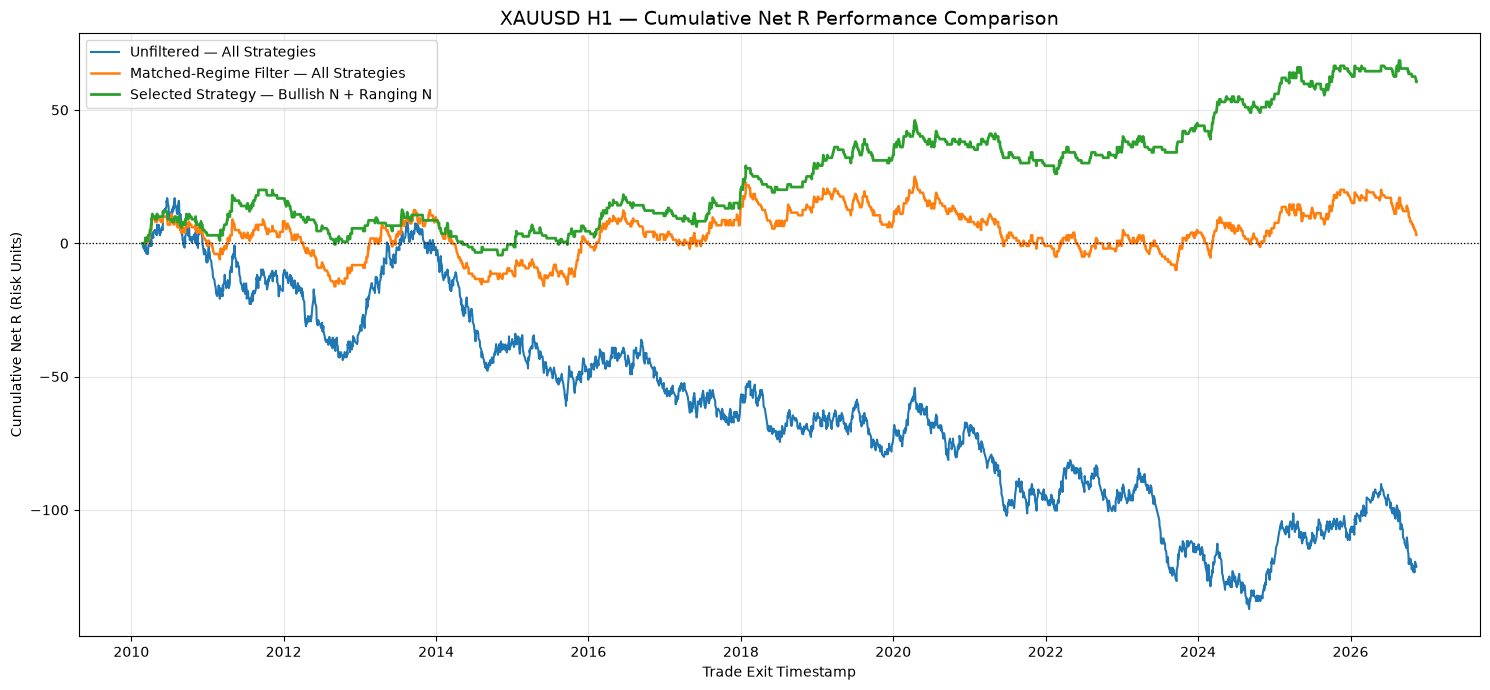

Chart saved to: /Users/febrianamisdianti/Documents/XAUUSD_regime_analysis_on_n_pattern/assets/h1_cumulative_r_three_way_comparison.png
Time-series data saved to: /Users/febrianamisdianti/Documents/XAUUSD_regime_analysis_on_n_pattern/outputs/XAUUSD_H1_cumulative_R_three_way_comparison.csv


,Selection,Trades,Final Net R
0,Unfiltered — All Strategies,2946,-121.391
1,Matched-Regime Filter — All Strategies,977,3.125
2,Bullish N + Ranging N only,614,60.536


In [8]:
# ============================================================
# Cumulative Performance: Unfiltered vs Regime-Filtered
# vs Bullish + Sideways Only
# ============================================================

ASSET_DIR = PROJECT_ROOT / "assets"
ASSET_DIR.mkdir(parents=True, exist_ok=True)

# 1. Define the three trade universes

# All valid trades, without regime filtering
unfiltered = valid.copy()

# Matched-regime filter:
# Bullish N -> Bullish
# Bearish N -> Bearish
# Ranging N -> Sideways
matched_filtered = matched_all.copy()

# Selected trading strategy:
# Bullish N -> Bullish regime
# Ranging N -> Sideways regime
# Bearish N -> Excluded
bullish_sideways_only = valid[
    (
        (valid["setup"] == "bullish") &
        (valid["Regime"] == "Bullish")
    ) |
    (
        (valid["setup"] == "ranging") &
        (valid["Regime"] == "Sideways")
    )
].copy()


# 2. Calculate cumulative Net R by trade exit timestamp

def cumulative_r_curve(frame, start_time):
    """
    Aggregate trade R by exit timestamp and calculate cumulative R.
    OPEN_AT_END trades remain included as final mark-to-market observations.
    """
    if frame.empty:
        return pd.Series(dtype=float)

    increments = (
        frame.groupby("exit_date")["R"]
        .sum()
        .sort_index()
    )

    start_time = pd.Timestamp(start_time)

    # Ensure all curves start from zero
    if start_time not in increments.index:
        increments.loc[start_time] = 0.0

    increments = increments.groupby(level=0).sum().sort_index()

    return increments.cumsum()


start_time = data.index.min()

unfiltered_curve = cumulative_r_curve(unfiltered, start_time)
matched_curve = cumulative_r_curve(matched_filtered, start_time)
selected_curve = cumulative_r_curve(bullish_sideways_only, start_time)


# 3. Align all curves on a common timeline
curve_comparison = pd.concat(
    [
        unfiltered_curve.rename("Unfiltered"),
        matched_curve.rename("Matched-regime filter"),
        selected_curve.rename("Bullish N + Ranging N only"),
    ],
    axis=1
).sort_index()

curve_comparison = curve_comparison.ffill().fillna(0.0)


# 4. Plot the three cumulative performance curves

plt.figure(figsize=(15, 7))

plt.plot(
    curve_comparison.index,
    curve_comparison["Unfiltered"],
    label="Unfiltered — All Strategies",
    linewidth=1.5
)

plt.plot(
    curve_comparison.index,
    curve_comparison["Matched-regime filter"],
    label="Matched-Regime Filter — All Strategies",
    linewidth=1.8
)

plt.plot(
    curve_comparison.index,
    curve_comparison["Bullish N + Ranging N only"],
    label="Selected Strategy — Bullish N + Ranging N",
    linewidth=2.0
)

plt.axhline(0, color="black", linewidth=0.9, linestyle=":")

plt.title(
    "XAUUSD H1 — Cumulative Net R Performance Comparison",
    fontsize=14
)
plt.xlabel("Trade Exit Timestamp")
plt.ylabel("Cumulative Net R (Risk Units)")

plt.grid(True, alpha=0.3)
plt.legend(loc="best")
plt.tight_layout()

chart_path = ASSET_DIR / "h1_cumulative_r_three_way_comparison.png"

plt.savefig(
    chart_path,
    dpi=160,
    bbox_inches="tight"
)

plt.show()


# 5. Export cumulative performance data

csv_path = OUTPUT_DIR / "XAUUSD_H1_cumulative_R_three_way_comparison.csv"

curve_comparison.rename_axis("exit_date").to_csv(csv_path)

print(f"Chart saved to: {chart_path}")
print(f"Time-series data saved to: {csv_path}")


# 6. Print trade counts and final cumulative Net R

summary = pd.DataFrame({
    "Selection": [
        "Unfiltered — All Strategies",
        "Matched-Regime Filter — All Strategies",
        "Bullish N + Ranging N only"
    ],
    "Trades": [
        len(unfiltered),
        len(matched_filtered),
        len(bullish_sideways_only)
    ],
    "Final Net R": [
        unfiltered["R"].sum(),
        matched_filtered["R"].sum(),
        bullish_sideways_only["R"].sum()
    ]
})

display(summary.round(3))

In [7]:
# Export analysis tables and trade-level regime labels.
regime_distribution.to_csv(OUTPUT_DIR / "XAUUSD_H1_regime_distribution.csv")
regime_performance.to_csv(OUTPUT_DIR / "XAUUSD_H1_regime_performance.csv", index=False)
comparison.to_csv(OUTPUT_DIR / "XAUUSD_H1_regime_filter_vs_baseline.csv", index=False)
trades.to_csv(OUTPUT_DIR / "XAUUSD_H1_N_method_trades_with_regime.csv", index=False)
print("Exported regime distribution, conditional performance, filter comparison, and trade-level labels.")

Exported regime distribution, conditional performance, filter comparison, and trade-level labels.


## 4. Interpretation and limitations

- **Lagging labels:** EMA and ADX are lagging indicators; regime changes may be recognized after the market has already begun transitioning.
- **Historical association, not causation:** conditional results do not prove that the regime caused the strategy outcome.
- **Trade counts matter:** subgroup performance can be unstable, even with more observations than the D1 study.
- **Costs are excluded:** H1 trading is especially sensitive to spread, commission, and slippage. The apparent edge may disappear after costs.
- **Portfolio overlap:** each N-Method strategy is evaluated independently. Combined results do not enforce shared capital or simultaneous exposure limits.
- **No out-of-sample validation:** no part of this exploratory result should be described as live validated or deployment-ready.

The research question remains: **Does regime classification improve the N-Method's risk-adjusted performance on data that was never used to design the rules?** The next stage is chronological out-of-sample / walk-forward evaluation, followed by forward testing with broker-specific costs.